# Assignment 4 — MLOps pipeline for a Cora GCN (node classification)
Train → track → package → register/gate → serve → monitor → rollback.

In [1]:
import sys, os, shutil, json, torch, pandas as pd
sys.path.append("../src")
from fastapi.testclient import TestClient
from data import load_cora, hold_out_unseen, training_graph, make_snapshot
from model import normalize_rows
from tracking import run_experiment
from package import Predictor, val_accuracy
from registry import Registry, gate
from serve import create_app, validate, PredictRequest
from client import build_request, context_graph
from monitor import snapshot_metrics, calibrate, detect, linear_cka, permute_hidden
import viz
try:
    os.remove("../mlflow.db")      # clean demo; skipped if the file is locked or missing
except (FileNotFoundError, PermissionError):
    pass

c:\Users\PC\Documents\GNN-practical-assignments\.venv\Lib\site-packages\fastapi\testclient.py:1: StarletteDeprecationWarning: Using `httpx` with `starlette.testclient` is deprecated; install `httpx2` instead.
  from starlette.testclient import TestClient as TestClient  # noqa
c:\Users\PC\Documents\GNN-practical-assignments\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


## 1. Data + unseen nodes
200 test nodes are treated as *introduced after training*: they and all their edges are removed from the training graph.

In [2]:
data = load_cora("../data")
unseen = hold_out_unseen(data)
g = training_graph(data, unseen)
incident = torch.isin(data.edge_index, unseen).any(0).sum().item()
print("full graph :", data.num_nodes, "nodes,", data.edge_index.size(1), "directed edges")
print("train graph:", g.num_nodes, "nodes,", g.edge_index.size(1), "directed edges")
assert g.num_nodes == data.num_nodes - len(unseen) and g.edge_index.size(1) == data.edge_index.size(1) - incident
print("unseen nodes and their", incident, "incident directed edges are absent from the training graph")

full graph : 2708 nodes, 10556 directed edges
train graph: 2508 nodes, 9216 directed edges
unseen nodes and their 1340 incident directed edges are absent from the training graph


## 2. Untracked baseline

In [3]:
%run ../baseline/train_bare.py

test acc: 0.7429999709129333


**Limitations of the bare script:** no seed (different result every run), no record of parameters/metrics/code version/data version, no validation-based checkpointing, model file overwritten each run (no versions), no preprocessing or label mapping saved, no way to reload and verify, no comparison against a previous model, no API, no monitoring, no rollback.

## 3. Experiment tracking (MLflow) — 4 runs

2026/10/15 04:51:14 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/15 04:51:14 INFO mlflow.store.db.utils: Updating database tables
2026/10/15 04:51:18 INFO mlflow.tracking.fluent: Experiment with name 'cora-gcn' does not exist. Creating a new experiment.


,tags.mlflow.runName,params.seed,params.hidden,params.n_labels,metrics.best_val_acc,tags.git_commit,tags.dataset_id
0,degraded-7-labels,0,16,7,0.412,7e9b880,dc17322fedab
1,gcn-h64,0,64,None,0.806,c362e4a,dc17322fedab
2,gcn-h16,0,16,None,0.786,dc3c48e,dc17322fedab
3,weak-40-labels,0,16,40,0.590,dc3c48e,dc17322fedab


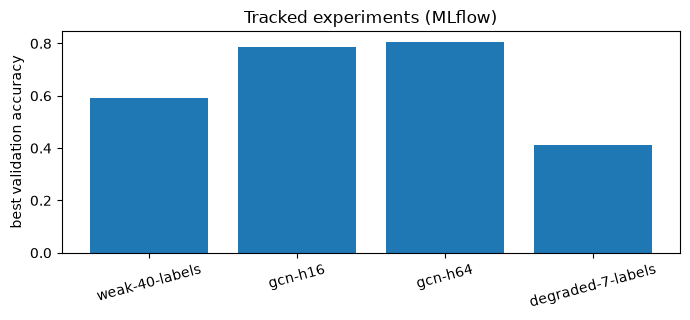

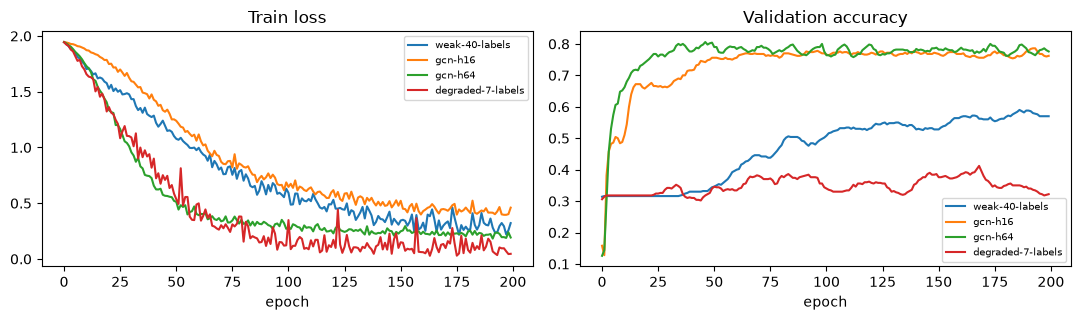

browse:  mlflow ui --backend-store-uri sqlite:///mlflow.db   (run from the assignment4 folder)


In [4]:
URI = "sqlite:///../mlflow.db"
LABELS = [f"class_{i}" for i in range(7)]          # replace with real topic names if you have them
CFG = dict(hidden=16, dropout=0.5, lr=0.01, wd=5e-4, epochs=200, n_labels=None, n_classes=7)
EXPS = {"weak-40-labels": dict(CFG, n_labels=40), "gcn-h16": CFG,
        "gcn-h64": dict(CFG, hidden=64), "degraded-7-labels": dict(CFG, n_labels=7)}
runs = {n: run_experiment(n, g, c, seed=0, labels=LABELS, out_dir="../artifacts", uri=URI) for n, c in EXPS.items()}
import mlflow; mlflow.set_tracking_uri(URI)
df = mlflow.search_runs(experiment_names=["cora-gcn"])
cols = ["tags.mlflow.runName", "params.seed", "params.hidden", "params.n_labels", "metrics.best_val_acc", "tags.git_commit", "tags.dataset_id"]
display(df[[c for c in cols if c in df]])
viz.plot_runs(df)
viz.plot_curves({n: r["hist"] for n, r in runs.items()})
print("browse:  mlflow ui --backend-store-uri sqlite:///mlflow.db   (run from the assignment4 folder)")

## 4. Model package + reload check

In [5]:
pkg = runs["gcn-h16"]["package"]
print(sorted(os.listdir(pkg)))
print(json.dumps({k: v for k, v in json.load(open(pkg / "meta.json")).items() if k != "labels"}, indent=1))
p1, p2 = Predictor(pkg), Predictor(pkg)
orig = runs["gcn-h16"]["model"](normalize_rows(g.x), g.edge_index)
assert torch.equal(p1.logits(g.x, g.edge_index), orig) and torch.equal(p1.logits(g.x, g.edge_index), p2.logits(g.x, g.edge_index))
print("reloaded model reproduces the original predictions exactly")

['meta.json', 'weights.pt']
{
 "architecture": {
  "name": "GCN",
  "d_in": 1433,
  "d_hid": 16,
  "d_out": 7,
  "dropout": 0.5
 },
 "preprocessing": "row_normalize: x / max(sum(x), 1)",
 "feature_schema": {
  "n_features": 1433,
  "dtype": "float32",
  "min_value": 0.0
 },
 "dataset_id": "dc17322fedab",
 "torch_version": "2.14.1+cpu",
 "version": "unregistered",
 "seed": 0,
 "git_commit": "dc3c48e",
 "mlflow_run_id": "f67ccb3fba634398b155f0b6f990fd1a"
}
reloaded model reproduces the original predictions exactly


## 5. Registry + validation gate
Metric: validation accuracy of candidate **and** approved model, recomputed on the same validation set. Rules: missing metric → block · below floor 0.40 → block · first model → promote · gain ≥ 0.005 → promote · tie / smaller gain → block · regression → block.

In [6]:
shutil.rmtree("../registry", ignore_errors=True)
reg = Registry("../registry")
ev = lambda path: val_accuracy(path, g)
for name in EXPS:
    v = reg.register(runs[name]["package"], {"val_acc": runs[name]["val_acc"]}, runs[name]["run_id"])
    print(f"{v} {name:18s}", reg.try_promote(v, ev).reason)
print("approved:", reg.approved, "| history:", reg.state["history"])

v1 weak-40-labels     PROMOTE: first model and above floor
v2 gcn-h16            PROMOTE: 0.786 vs approved 0.590 (gain +0.196)
v3 gcn-h64            PROMOTE: 0.806 vs approved 0.786 (gain +0.020)
v4 degraded-7-labels  BLOCKED: regression 0.412 < approved 0.806
approved: v3 | history: ['v1', 'v2', 'v3']


In [7]:
# every gate rule on its own
cases = [("candidate metric missing", None, 0.80, True), ("NaN metric", float("nan"), 0.80, True),
         ("first model", 0.70, None, False), ("first model below floor", 0.30, None, False),
         ("tie", 0.80, 0.80, True), ("small gain (0.002)", 0.802, 0.80, True),
         ("clear gain", 0.82, 0.80, True), ("regression", 0.75, 0.80, True), ("approved metric missing", 0.82, None, True)]
pd.DataFrame([dict(case=n, promote=gate(c, a, h).promote, reason=gate(c, a, h).reason) for n, c, a, h in cases])

,case,promote,reason
0,candidate metric missing,False,BLOCKED: candidate metric missing
1,NaN metric,False,BLOCKED: candidate metric missing
2,first model,True,PROMOTE: first model and above floor
3,first model below floor,False,BLOCKED: 0.300 is below the floor 0.4
4,tie,False,BLOCKED: gain +0.000 < required 0.005 (tie/noi...
5,small gain (0.002),False,BLOCKED: gain +0.002 < required 0.005 (tie/noi...
6,clear gain,True,PROMOTE: 0.820 vs approved 0.800 (gain +0.020)
7,regression,False,BLOCKED: regression 0.750 < approved 0.800
8,approved metric missing,False,"BLOCKED: approved model metric missing, cannot..."


## 6. Serving (FastAPI). Request = `features` (N×1433 raw), `edges`, `target_ids` (row numbers). Response includes `model_version`.
**Graph-context requirement:** the model is inductive, but every request must carry the nodes' features and their neighbourhood. A 2-layer GCN reproduces full-graph results exactly only with the **3-hop** neighbourhood (messages from 2 hops + degrees of the outer nodes).

{'status': 'ok', 'model_version': 'v3'}
{'seen': 0.8287500143051147, 'unseen': 0.8100000023841858}


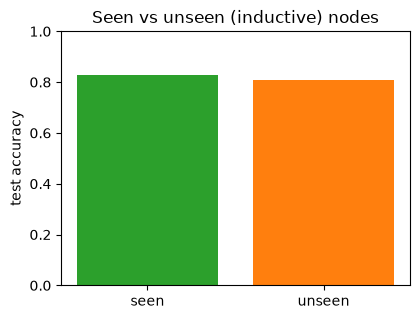

In [8]:
client = TestClient(create_app("../registry"))
print(client.get("/health").json())
pred = Predictor(reg.path(reg.approved))
test_idx = data.test_mask.nonzero().flatten()
seen_test = test_idx[~torch.isin(test_idx, unseen)]
out = pred.logits(data.x, data.edge_index).argmax(1)
acc = {"seen": (out[seen_test] == data.y[seen_test]).float().mean().item(),
       "unseen": (out[unseen] == data.y[unseen]).float().mean().item()}
print(acc); viz.plot_seen_unseen(acc)

In [9]:
ids = seen_test[:3].tolist() + unseen[:3].tolist()
payload, subset = build_request(data.x, data.edge_index, ids, hops=3)
r = client.post("/predict", json=payload).json()
print("model:", r["model_version"], "| context:", r["context"])
pd.DataFrame(r["predictions"]).assign(original_id=[int(subset[i]) for i in [p["id"] for p in r["predictions"]]],
                                      kind=["seen"]*3 + ["unseen"]*3, true=data.y[ids].tolist())

model: v3 | context: {'n_nodes': 775, 'n_edges': 1531}


,id,label,label_name,confidence,isolated,original_id,kind,true
0,485,1,class_1,0.185535,False,1708,seen,3
1,486,2,class_2,0.555741,False,1709,seen,2
2,487,2,class_2,0.336318,False,1710,seen,2
3,529,2,class_2,0.600422,False,1752,unseen,2
4,522,2,class_2,0.599320,False,1745,unseen,2
5,703,4,class_4,0.472682,False,2383,unseen,4


{1: 0.95, 2: 0.975, 3: 1.0}


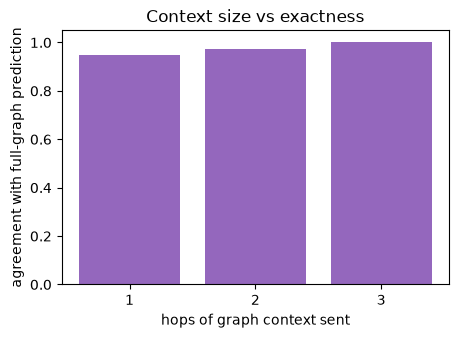

In [10]:
# how much context is needed?  agreement with the full-graph prediction on 40 unseen nodes
full = pred.logits(data.x, data.edge_index)
res = {}
for hops in (1, 2, 3):
    ok = 0
    for i in unseen[:40].tolist():
        xs, ei, loc, _ = context_graph(data.x, data.edge_index, [i], hops)
        ok += int(pred.logits(xs, ei)[loc].argmax(1) == full[i].argmax())
    res[hops] = ok / 40
print(res); viz.plot_hops(res)

**Limitations:** unseen nodes need their features **and** at least some edges; an isolated node is predicted from its own features only (flagged `isolated: true`). Too small a context changes degree normalisation and neighbour aggregation. Feature schema (1433 non-negative values) must match. Classes never seen in training cannot be predicted. The model learned on the training graph's degree/feature distribution (see drift).

In [11]:
# isolated unseen node: features only, no edges
i = int(unseen[0])
iso = client.post("/predict", json={"features": [data.x[i].tolist()], "edges": [], "target_ids": [0]}).json()["predictions"][0]
print("isolated:", iso, "| with neighbours:", r["predictions"][3], "| true label:", int(data.y[i]))

isolated: {'id': 0, 'label': 2, 'label_name': 'class_2', 'confidence': 0.5673792362213135, 'isolated': True} | with neighbours: {'id': 529, 'label': 2, 'label_name': 'class_2', 'confidence': 0.6004220247268677, 'isolated': False} | true label: 2


## 7. Failure handling

In [12]:
f = data.x[:3].tolist()
cases = {
 "isolated node":          (dict(features=f, edges=[[0, 1]], target_ids=[2]), "200, predicted from own features, isolated=true"),
 "duplicate target ids":   (dict(features=f, edges=[[0, 1]], target_ids=[0, 0]), "422 rejected"),
 "invalid edge endpoint":  (dict(features=f, edges=[[0, 9]], target_ids=[0]), "422 rejected"),
 "wrong feature dimension":(dict(features=[row[:10] for row in f], edges=[], target_ids=[0]), "422 rejected"),
 "unknown target id":      (dict(features=f, edges=[], target_ids=[7]), "422 rejected"),
}
rows = []
for name, (body, expected) in cases.items():
    resp = client.post("/predict", json=body); rows.append(dict(case=name, status=resp.status_code, expected=expected, body=str(resp.json())[:90]))
bad = TestClient(create_app("../does_not_exist")); resp = bad.post("/predict", json=cases["isolated node"][0])
rows.append(dict(case="model loading failure", status=resp.status_code, expected="503, /health also 503", body=str(resp.json())[:90]))
pd.DataFrame(rows)

,case,status,expected,body
0,isolated node,200,"200, predicted from own features, isolated=true","{'model_version': 'v3', 'predictions': [{'id':..."
1,duplicate target ids,422,422 rejected,{'error': 'duplicate target_ids'}
2,invalid edge endpoint,422,422 rejected,{'error': 'invalid edge endpoint: edges are [u...
3,wrong feature dimension,422,422 rejected,{'error': 'features must be an N x 1433 matrix'}
4,unknown target id,422,422 rejected,{'error': 'unknown target id: valid ids are 0....
5,model loading failure,503,"503, /health also 503",{'error': 'model unavailable: no approved mode...


## 8. Prediction consistency: offline == API (same inputs, context, preprocessing, model version)

In [13]:
ids = seen_test[:5].tolist() + unseen[:5].tolist()
payload, subset = build_request(data.x, data.edge_index, ids, hops=3)
api = client.post("/predict", json=payload).json()
x, e, loc = validate(PredictRequest(**payload), pred.n_features)
off_same_input = pred.predict(x, e, loc)                                   # same payload, offline
off_full = pred.predict(data.x, data.edge_index, torch.tensor(ids))        # whole graph, offline
for a, b, c in zip(api["predictions"], off_same_input, off_full):
    assert a["label"] == b["label"] == c["label"] and abs(a["confidence"] - b["confidence"]) < 1e-9 and abs(a["confidence"] - c["confidence"]) < 1e-5
print("API == offline (same payload) == offline (full graph) for", len(ids), "nodes incl. unseen")

API == offline (same payload) == offline (full graph) for 10 nodes incl. unseen


## 9. Drift detection (fixed model = approved version)
Graph statistic: relative change of mean degree. Embedding statistic: 1 − mean cosine(old, new hidden embedding) per node. Threshold = max(mean + 3σ, 1.5×mean) of 10 *normal* snapshots (5 % random edges missing) → above normal noise, far below real change.

thresholds: {'degree_change': 0.0758, 'embedding_shift': 0.0009}
normal : {'degree_change': 0.0476, 'embedding_shift': 0.0006} -> {'degree_change': False, 'embedding_shift': False}
drifted: {'degree_change': 0.5081, 'embedding_shift': 0.0184} -> {'degree_change': True, 'embedding_shift': True}


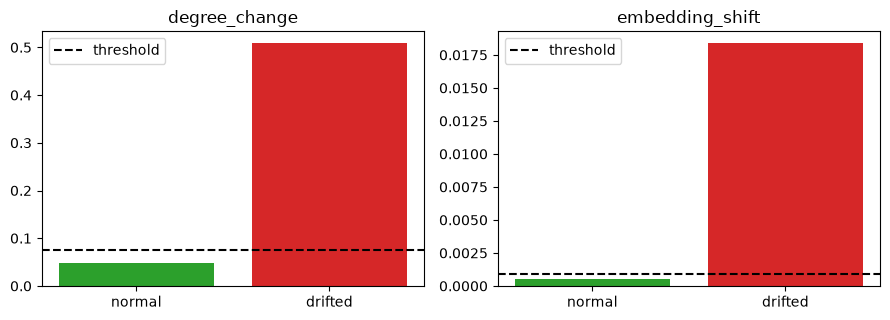

In [14]:
ref = (data.x, data.edge_index)
normal_runs = [snapshot_metrics(pred, ref, make_snapshot(data, edge_drop=0.05, seed=s)) for s in range(10)]
thr = calibrate(normal_runs)
normal = snapshot_metrics(pred, ref, make_snapshot(data, edge_drop=0.05, seed=100))
drift = snapshot_metrics(pred, ref, make_snapshot(data, edge_drop=0.5, feat_drop=0.3, seed=100))
print("thresholds:", {k: round(v, 4) for k, v in thr.items()})
print("normal :", {k: round(v, 4) for k, v in normal.items()}, "->", detect(normal, thr))
print("drifted:", {k: round(v, 4) for k, v in drift.items()}, "->", detect(drift, thr))
viz.plot_drift(thr, normal, drift)

### Why raw embeddings of different model versions are not comparable

In [15]:
m = pred.model; x = normalize_rows(data.x)
m2 = permute_hidden(m, torch.randperm(m.c1.bias.numel(), generator=torch.Generator().manual_seed(0)))   # same function, relabelled units
(o1, z1), (o2, z2) = m(x, data.edge_index, return_emb=True), m2(x, data.edge_index, return_emb=True)
print("same predictions       :", torch.allclose(o1, o2, atol=1e-5))
print("raw coordinate cosine  :", round(torch.nn.functional.cosine_similarity(z1, z2, dim=1).mean().item(), 3), "(not 1)")
print("linear CKA             :", round(linear_cka(z1, z2), 3), "(geometry identical)")

same predictions       : True
raw coordinate cosine  : 0.747 (not 1)
linear CKA             : 1.0 (geometry identical)


Hidden units have no fixed meaning: any permutation/rotation of them gives an equally good model, and different seeds or versions land in different coordinate systems. Compare **outputs/probabilities** or a rotation-invariant similarity (CKA), or monitor drift with one fixed model, as above.

## 10. Rollback

In [16]:
best = reg.approved
print("serving:", client.get("/health").json())
print("rollback ->", reg.rollback())
print("after /reload:", client.post("/reload").json())
reg.promote(best); print("restored:", client.post("/reload").json())

serving: {'status': 'ok', 'model_version': 'v3'}
rollback -> v2
after /reload: {'status': 'ok', 'model_version': 'v2'}
restored: {'status': 'ok', 'model_version': 'v3'}


## 11. Tests, Docker, CI
* `pytest ../tests -q`
* Commit `registry/` after running this notebook, then: `docker build -t cora-gcn .` · `docker run -p 8000:8000 cora-gcn` · `curl localhost:8000/health`
* `.github/workflows/ci.yml` runs the tests and `scripts/gate.py` on every push; a blocked gate exits 1 and fails the job. Demonstrate with `python scripts/gate.py --n-labels 7` (blocked) vs `python scripts/gate.py` (passes).

## 12. Significant implementation problem (write yours)
Problem → how I investigated → how I fixed it.

In [17]:
!pytest ../../tests/test_assignment4.py -q

........................................                                 [100%]
============================== warnings summary ===============================
..\..\.venv\Lib\site-packages\fastapi\testclient.py:1
  C:\Users\PC\Documents\GNN-practical-assignments\.venv\Lib\site-packages\fastapi\testclient.py:1: StarletteDeprecationWarning: Using `httpx` with `starlette.testclient` is deprecated; install `httpx2` instead.
    from starlette.testclient import TestClient as TestClient  # noqa

..\..\.venv\Lib\site-packages\torch\jit\_script.py:1491
  C:\Users\PC\Documents\GNN-practical-assignments\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
    warnings.warn(

tests/test_assignment4.py: 1124 warnings
  C:\Users\PC\Documents\GNN-practical-assignments\.venv\Lib\site-packages\torch_geometric\inspector.py:433: DeprecationWarning: Failing to pass a value to the 'type_params' parameter of